


#Assembling ...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/bempp_cl/api/assembly/discrete_boundary_operator.py:619: SparseEfficiencyWarning: splu converted its input to CSC format
  solver = solver_interface(actual_mat)


#Solving ...
# th=0


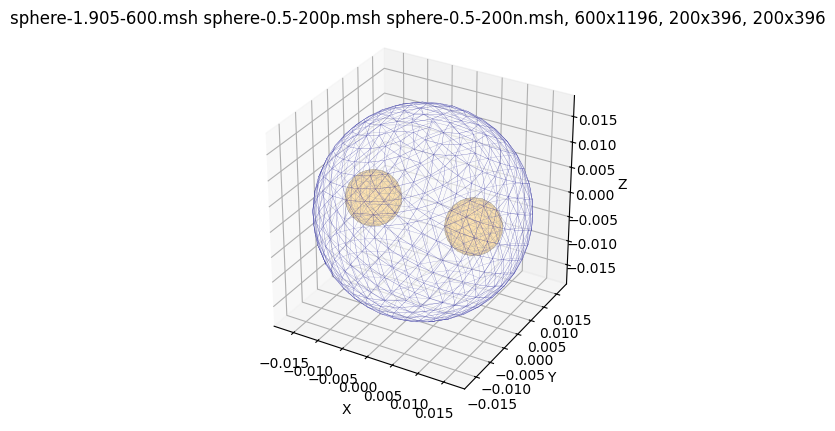

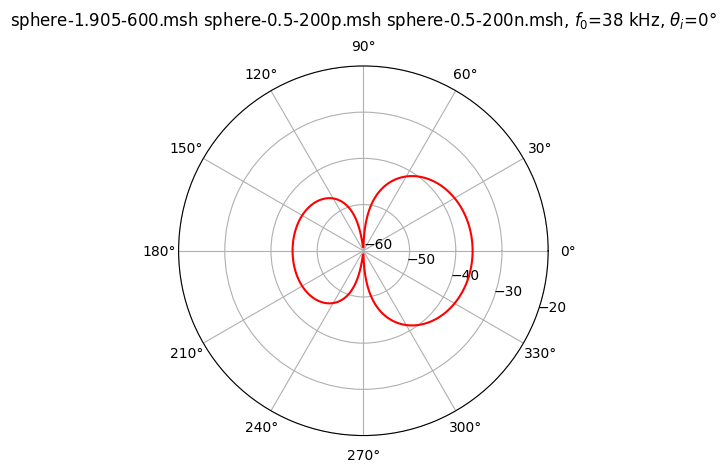

0	0.0152105
1	0.0152091
2	0.0152049
3	0.0151979
4	0.0151881
5	0.0151755
6	0.01516
7	0.0151416
8	0.0151203
9	0.0150961
10	0.0150688
11	0.0150385
12	0.015005
13	0.0149684
14	0.0149286
15	0.0148854
16	0.0148389
17	0.0147889
18	0.0147355
19	0.0146784
20	0.0146176
21	0.0145531
22	0.0144847
23	0.0144125
24	0.0143362
25	0.0142558
26	0.0141712
27	0.0140824
28	0.0139892
29	0.0138916
30	0.0137896
31	0.0136829
32	0.0135716
33	0.0134556
34	0.0133348
35	0.0132092
36	0.0130788
37	0.0129434
38	0.012803
39	0.0126577
40	0.0125073
41	0.0123519
42	0.0121915
43	0.012026
44	0.0118555
45	0.01168
46	0.0114994
47	0.011314
48	0.0111236
49	0.0109284
50	0.0107284
51	0.0105237
52	0.0103144
53	0.0101007
54	0.00988248
55	0.00966002
56	0.00943343
57	0.00920285
58	0.00896842
59	0.00873033
60	0.00848873
61	0.00824381
62	0.00799577
63	0.00774482
64	0.00749115
65	0.007235
66	0.00697659
67	0.00671616
68	0.00645395
69	0.00619022
70	0.00592522
71	0.00565921
72	0.00539247
73	0.00512528
74	0.00485792
75	0.00459068
76	0.00432

In [5]:
# MM 20.7.2025: scattering from three spheres - double transmission problem
# !pip install --force-reinstall "numpy<=2.2" scipy bempp-cl matplotlib

repo_name = "mm-bem"
repo_url = f"https://github.com/marmoszy/{repo_name}.git"
import os
if not os.path.exists(repo_name): 
    !git clone {repo_url}
os.chdir(f"{repo_name}/msh")

import bempp_cl as bempp
from bempp_cl.api.operators.boundary import helmholtz as boundary, sparse
from bempp_cl.api.operators.potential import helmholtz as potential
from scipy.sparse.linalg import gmres
from numpy import pi, sin, cos, exp, abs, log10, array, linspace, block

# --- input parameters
# fname1,fname2,#fname3 = "src/mesh1.msh","src/mesh2.msh","src/mesh3.msh"
fname1 = "sphere-1.905-600.msh"
fname2 = "sphere-0.5-200p.msh"
fname3 = "sphere-0.5-200n.msh"

th0 = [0]
f0, c0, rho0 = 38e3,    1480, 1024  # sea water
a1, c1, rho1 = 0.01905, 1540, 1045  # external fluid bubble
a2, c2, rho2 = 0.005,    340, 1.29  # internal air bubble
a3, c3, rho3 = 0.005,    340, 1.29  # internal air bubble

# --- target meshes and its spaces
#grid1 = bempp.api.shapes.sphere(r=a1, h=c0/f0/5, origin=(    0,0,0))
#grid2 = bempp.api.shapes.sphere(r=a2, h=c0/f0/5, origin=( 0.01,0,0)) #  offset
#grid3 = bempp.api.shapes.sphere(r=a3, h=c0/f0/5, origin=(-0.01,0,0)) # -offset
grid1 = bempp.api.import_grid(fname1)
grid2 = bempp.api.import_grid(fname2)
grid3 = bempp.api.import_grid(fname3)

Sp1 = bempp.api.function_space(grid1, "P", 1)
Sp2 = bempp.api.function_space(grid2, "P", 1)
Sp3 = bempp.api.function_space(grid3, "P", 1)

# --- calculated values
k0, k1, k2, k3 = 2*pi*f0/c0, 2*pi*f0/c1, 2*pi*f0/c2, 2*pi*f0/c3
N1,N2,N3 = Sp1.global_dof_count,Sp2.global_dof_count,Sp3.global_dof_count
z2, z3 = array([0]*N2), array([0]*N3)

# --- scaled helmholtz operators
def operators(Sp1, Sp2, k, rho, s=0):
      S = boundary.single_layer(Sp1, Sp2, Sp2, k)
      D = boundary.double_layer(Sp1, Sp2, Sp2, k)
      T = boundary.adjoint_double_layer(Sp1, Sp2, Sp2, k)
      H = boundary.hypersingular(Sp1, Sp2, Sp2, k)
      if s != 0:
            I = s/2 * sparse.identity(Sp1, Sp1, Sp1)
            D, T = D+I, T-I
      return (rho*rho*S, rho*D, -rho*T, H)

print("#Assembling ...") #,file=sys.stderr,flush=True)
(S0, D0, T0, H0) = operators(Sp1, Sp1, k0, rho0,  1)
(S1, D1, T1, H1) = operators(Sp1, Sp1, k1, rho1, -1)
(S2, D2, T2, H2) = operators(Sp2, Sp1, k1, rho1)
(S3, D3, T3, H3) = operators(Sp1, Sp2, k1, rho1)
(S4, D4, T4, H4) = operators(Sp2, Sp2, k1, rho1,  1)
(S5, D5, T5, H5) = operators(Sp2, Sp2, k2, rho2, -1)
(S6, D6, T6, H6) = operators(Sp3, Sp1, k1, rho1)
(S7, D7, T7, H7) = operators(Sp1, Sp3, k1, rho1)
(S8, D8, T8, H8) = operators(Sp3, Sp3, k1, rho1,  1)
(S9, D9, T9, H9) = operators(Sp3, Sp3, k3, rho3, -1)
Z23 = 0 * operators(Sp3, Sp2, k3, rho3)[0]  # N2 x N3 zeros operator
Z32 = 0 * operators(Sp2, Sp3, k3, rho3)[0]  # N3 x N2 zeros operator

# --- kernel matrix
A = [[ D0-D1, S0-S1,  -D2,   -S2,   -D6,    -S6 ],
     [ H0-H1, T0-T1,  -H2,   -T2,   -H6,    -T6 ],
     [   D3,    S3,  D4-D5, S4-S5,  Z23,    Z23 ],
     [   H3,    T3,  H4-H5, T4-T5,  Z23,    Z23 ],
     [   D7,    S7,   Z32,   Z32,  D8-D9, S8-S9 ],
     [   H7,    T7,   Z32,   Z32,  H8-H9, T8-T9 ]]
A = [[bempp.api.as_matrix(x.strong_form()) for x in a] for a in A]

print("#Solving ...") #,file=sys.stderr,flush=True)
for th in th0:
      print("# th=%d"%(th)) #,end=' ') #,file=sys.stderr,flush=True)
      
      # --- plane wave direction
      d = array([cos(pi/180*th),sin(pi/180*th),0])

      # --- incident pressure and its normal derivative
      @bempp.api.complex_callable
      def pinc(x, n, idx, res): res[0]=exp(1j*k0*d.dot(x))
      f = bempp.api.GridFunction(Sp1, fun=pinc).coefficients
      @bempp.api.complex_callable
      def dpinc(x, n, idx, res): res[0]=1j*k0*exp(1j*k0*d.dot(x))*d.dot(n)
      g = bempp.api.GridFunction(Sp1, fun=dpinc).coefficients

      # --- surface solution
      u,_ = gmres(block(A), block([[-f, g/rho0, z2, z2, z3, z3]]).T)
      psi = bempp.api.GridFunction(Sp1, coefficients=u[0: N1 ])
      phi = bempp.api.GridFunction(Sp1, coefficients=u[N1:2*N1])

      # --- far field solution
      r1 = array([[cos(2*pi*i/360),sin(2*pi*i/360),0] for i in range(360)]).T
      SL = rho0**2 * potential.single_layer(Sp1, r1, k0)
      DL = rho0    * potential.double_layer(Sp1, r1, k0)
      psc = DL * psi + SL * phi 

      # plot mesh
      import matplotlib.pyplot as plt
      from mpl_toolkits.mplot3d.art3d import Poly3DCollection
      fig = plt.figure()
      ax = fig.add_subplot(111, projection='3d')
 
      v = grid1.vertices.T  # Transpose to shape (N, 3)
      e = grid1.elements.T  # Transpose to shape (M, 3)
      n,m = len(v),len(e)
      tri = [[array(v[i]) for i in t] for t in e]
      mesh_collection = Poly3DCollection(tri, alpha=0.4)
      mesh_collection.set_facecolor('white')
      mesh_collection.set_edgecolor('darkblue')
      mesh_collection.set_linewidth(0.2)
      ax.add_collection3d(mesh_collection)
 
      v2 = grid2.vertices.T  # Transpose to shape (N, 3)
      e2 = grid2.elements.T  # Transpose to shape (M, 3)
      n2,m2 = len(v2),len(e2)
      tri2 = [[array(v2[i]) for i in t] for t in e2]
      mesh_collection2 = Poly3DCollection(tri2, alpha=0.6)
      mesh_collection2.set_facecolor('orange')
      mesh_collection2.set_edgecolor('black')
      mesh_collection2.set_linewidth(0.2)
      ax.add_collection3d(mesh_collection2)

      v3 = grid3.vertices.T  # Transpose to shape (N, 3)
      e3 = grid3.elements.T  # Transpose to shape (M, 3)
      n3,m3 = len(v3),len(e3)
      tri3 = [[array(v3[i]) for i in t] for t in e3]
      mesh_collection3 = Poly3DCollection(tri3, alpha=0.6)
      mesh_collection3.set_facecolor('orange')
      mesh_collection3.set_edgecolor('black')
      mesh_collection3.set_linewidth(0.2)
      ax.add_collection3d(mesh_collection3)

      v_arr = array(v)
      ax.set_xlim(v_arr[:, 0].min(), v_arr[:, 0].max())
      ax.set_ylim(v_arr[:, 1].min(), v_arr[:, 1].max())
      ax.set_zlim(v_arr[:, 2].min(), v_arr[:, 2].max())
      ax.set_box_aspect((1, 1, 1))
      ax.set_xlabel('X')
      ax.set_ylabel('Y')
      ax.set_zlabel('Z')
      ax.set_title(r"%s %s %s, %dx%d, %dx%d, %dx%d"%(fname1,fname2,fname3,n,m,n2,m2,n3,m3))
      plt.show()

      # plot solution
      import matplotlib.pyplot as plt
      angles = linspace(0, 2 * pi, 360, endpoint=False)
      values_db = 20 * log10([abs(p) for p in psc[0]])
      vmin, vmax = -60, -20
      fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
      ax.plot(angles, values_db, color='red')
      ax.set_ylim(vmin, vmax)
      ax.set_rticks(linspace(vmin, vmax, 5))
      ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
      ax.set_rlabel_position(-20)
      ax.grid(True)
      ax.set_title(r"%s %s %s, $f_0$=%g kHz, $\theta_i$=%g$\degree$"%(fname1,fname2,fname3,f0/1e3,th), va='bottom')
      plt.show()

      # print                  
      print("\n".join(["%d\t%g"%(i,abs(psc[0][i])) for i in range(len(psc[0]))]))


